# 03 · Trayectorias salariales

Estimación y validación de `pension_mc.wages` con los cotizantes de la GEIH 2022–2025:

1. **Tobit heterocedástico** para el log del salario real, censurado en el salario mínimo. Un tercio de los cotizantes gana el mínimo; muchos lo declaran junto con el auxilio de transporte, que no hace parte del IBC.
2. **Descomposición de la dispersión** en un componente permanente (α) y un choque persistente AR(1), identificados por cómo crece la varianza con la edad.
3. **Simulación** de trayectorias, con o sin el salario actual de la persona.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pension_mc import wages as W
from pension_mc.config import DATA_PROCESSED as P, parametros

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
AZUL = {"150": "#b7d3f6", "250": "#86b6ef", "650": "#104281"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})

def mediana_ponderada(v, w):
    o = np.argsort(v); v, w = np.asarray(v)[o], np.asarray(w)[o]
    c = np.cumsum(w)
    return v[np.searchsorted(c, c[-1] / 2)]

def percentiles_ponderados(v, w, qs):
    o = np.argsort(v); v, w = np.asarray(v)[o], np.asarray(w)[o]
    c = np.cumsum(w) / w.sum()
    return [v[min(np.searchsorted(c, q / 100), len(v) - 1)] for q in qs]

geih = pd.read_parquet(P / "geih_pensiones.parquet")
ipc = pd.read_parquet(P / "ipc_mensual.parquet")
d = W.muestra(geih, ipc)
SMMLV_2026 = parametros()["smmlv"]["valores"][2026]
MILL = 1e6
d["deflactor"] = np.exp(d.y) / d.ingreso_laboral
print(f"{len(d):,} cotizantes de 18 a 65 años con ingreso; pesos reales de {ipc.fecha.iloc[-1]:%Y-%m}")

583,208 cotizantes de 18 a 65 años con ingreso; pesos reales de 2026-09


## 1. Censura en el salario mínimo

In [2]:
tab = (d.groupby(["educ", "sexo"]).apply(lambda g: pd.Series({
            "observaciones": len(g),
            "gana_el_minimo": np.average(g.censurado, weights=g.fex)}), include_groups=False)
        .unstack("sexo"))
tab = tab.reindex(W.NIVELES)
tab.style.format({c: ("{:,.0f}" if c[0] == "observaciones" else "{:.1%}") for c in tab.columns})

Se considera que gana el mínimo quien declara hasta *mínimo + auxilio de transporte + 2 %*: en la GEIH hay amontonamiento tanto en 1,00 como en 1,12–1,16 SMMLV (el auxilio).

Una regresión de mínimos cuadrados sobre el log del salario trataría esa masa de personas en el mínimo como si su salario "verdadero" fuera exactamente el mínimo. Eso aplana el perfil de edad y subestima la dispersión de los grupos menos educados, que son más de la mitad en el mínimo. El Tobit trata esas observaciones como "salario latente ≤ mínimo".

## 2. Estimación

In [3]:
m = W.estimar(geih, ipc)
print(f"Tobit: {m.n_obs:,} observaciones, {m.proporcion_censurada:.1%} censuradas, log-verosimilitud {m.log_verosimilitud:,.0f}")
print("Efectos de año (log, vs 2022):", dict(zip(m.anios[1:], np.round(m.beta[-len(m.anios) + 1:], 3))))

Tobit: 583,208 observaciones, 41.2% censuradas, log-verosimilitud -509,840
Efectos de año (log, vs 2022): {2023: np.float64(-0.019), 2024: np.float64(0.02), 2025: np.float64(0.044)}


### 2.1 Perfil edad-salario (percentil 75, en millones de pesos de 2026)

Se grafica el P75 porque en los grupos sin educación superior la mediana es el salario mínimo a casi cualquier edad. Puntos: P75 observado en la GEIH 2025. Líneas: P75 que implica el modelo. En ambos casos, quien no supera el umbral (mínimo + auxilio) cuenta como salario mínimo. La línea punteada es el salario mínimo de 2025 en pesos de 2026.

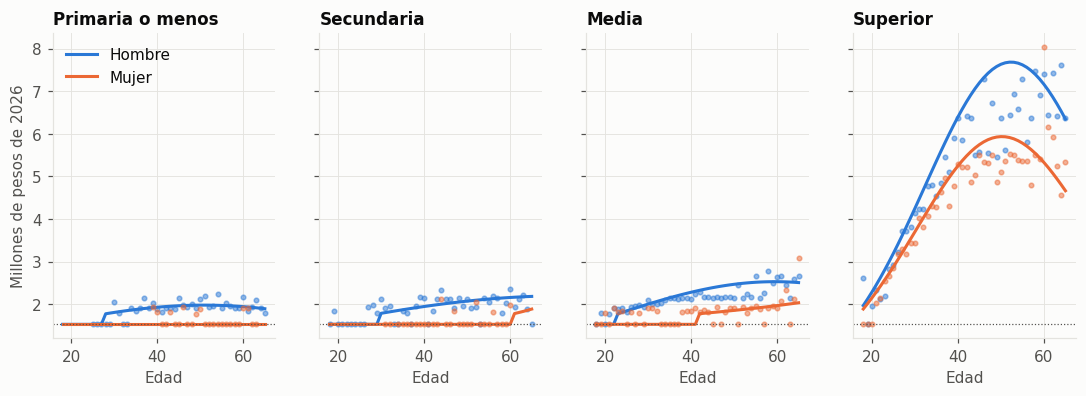

In [4]:
d25 = d[d.anio == 2025].copy()
piso25 = np.average(d25.smlv * d25.deflactor, weights=d25.fex)      # mínimo de 2025 en pesos de 2026
umbral25 = np.exp(np.average(d25.c, weights=d25.fex))                # mínimo + auxilio + 2 %
d25["w_obs"] = np.where(d25.censurado, piso25, np.exp(d25.y))
al_piso = lambda w: np.where(w <= umbral25, piso25, w)
edades = np.arange(18, 66)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6), sharey=True)
for ax, e in zip(axes, W.NIVELES):
    for i, s in enumerate(W.SEXOS):
        g = d25[(d25.educ == e) & (d25.sexo == s)]
        obs = g.groupby("edad").apply(lambda x: percentiles_ponderados(x.w_obs, x.fex, [75])[0], include_groups=False)
        obs = obs[g.groupby("edad").size() >= 30]
        ax.plot(obs.index, obs / MILL, "o", ms=3, color=SERIES[i], alpha=0.5)
        p75 = np.exp(m.log_media(edades, s, e) + 0.6745 * m.sigma(edades, s, e))
        ax.plot(edades, al_piso(p75) / MILL, color=SERIES[i], label=s)
    ax.axhline(piso25 / MILL, color=INK2, lw=0.8, ls=":")
    ax.set_title(e, fontsize=11)
    ax.set_xlabel("Edad")
axes[0].set_ylabel("Millones de pesos de 2026")
axes[0].legend(loc="upper left")
plt.show()

### 2.2 Dispersión por edad: Tobit (línea continua) vs. modelo α + AR(1) (línea discontinua)

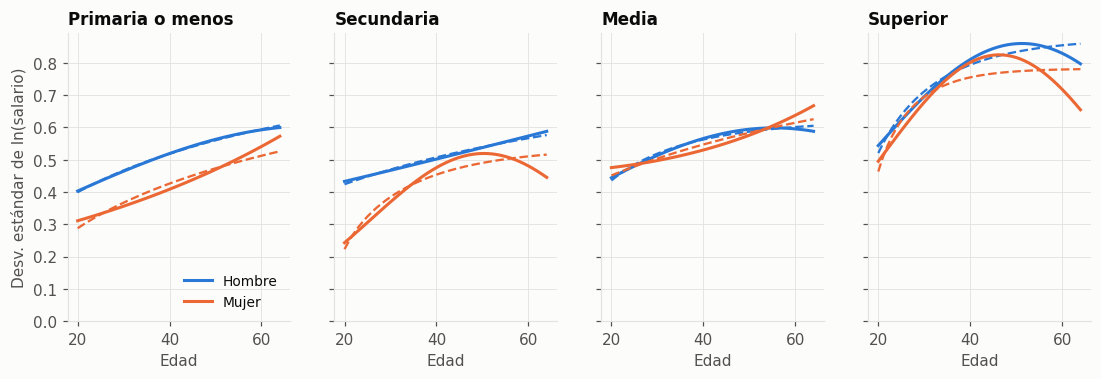

In [5]:
ed = np.arange(20, 65)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, e in zip(axes, W.NIVELES):
    for i, s in enumerate(W.SEXOS):
        ax.plot(ed, m.sigma(ed, s, e), color=SERIES[i], label=s)
        ax.plot(ed, np.sqrt(W.varianza_ar(ed, *m.ar[W.clave(e, s)])), color=SERIES[i], ls="--", lw=1.5)
    ax.set_title(e, fontsize=11)
    ax.set_xlabel("Edad")
axes[0].set_ylabel("Desv. estándar de ln(salario)")
axes[0].set_ylim(0)
axes[0].legend(loc="lower right", fontsize=9)
plt.show()

par = pd.DataFrame({(e, s): {"σα (permanente)": m.ar[W.clave(e, s)][0], "σε (choque anual)": m.ar[W.clave(e, s)][1],
                             "ρ (persistencia anual)": m.ar[W.clave(e, s)][2],
                             "vida media del choque (años)": np.log(0.5) / np.log(m.ar[W.clave(e, s)][2]),
                             "% varianza permanente a los 40": m.ar[W.clave(e, s)][0] ** 2 / W.varianza_ar(40, *m.ar[W.clave(e, s)])}
                    for e, s in W._tipos()}).T
par.style.format({"σα (permanente)": "{:.3f}", "σε (choque anual)": "{:.3f}", "ρ (persistencia anual)": "{:.3f}",
                  "vida media del choque (años)": "{:.0f}", "% varianza permanente a los 40": "{:.0%}"})

- Los choques salariales son muy persistentes en todos los grupos (ρ entre 0,95 y 0,995): **quien empieza abajo tiende a quedarse abajo**.
- En educación superior los choques anuales son 2 a 3 veces más grandes (σε ≈ 0,19–0,24) y la dispersión se abre rápido entre los 20 y los 40 años: las carreras profesionales se separan.
- En algunos grupos la dispersión estimada por el Tobit *baja* después de los 50–55 años, probablemente por salida selectiva (quienes se pensionan dejan de cotizar). Un AR(1) no puede reproducir una varianza decreciente, así que el modelo sobreestima un poco la dispersión cerca del retiro.
- **La división entre α y z está débilmente identificada** (p. ej. la parte permanente es 7 % en secundaria-mujeres y 65 % en secundaria-hombres). Imponer una ρ común empeora mucho el ajuste de la varianza (hasta 0,46 en log), así que se mantienen los ajustes por tipo. La división solo importa al condicionar en el salario actual; se evaluará en el análisis de sensibilidad.

## 3. Validación: sección transversal simulada vs. GEIH 2025

Para cada tipo (educación × sexo) y edad se simulan 20.000 personas sin condicionar, sin crecimiento, y se aplica el piso del salario mínimo de 2025. La tabla compara los percentiles y la proporción en el mínimo con los observados.

In [6]:
filas = []
for e in W.NIVELES:
    for s in W.SEXOS:
        for edad in (25, 40, 55):
            g = d25[(d25.educ == e) & (d25.sexo == s) & d25.edad.between(edad - 2, edad + 2)]
            if len(g) < 200:
                continue
            p_obs = percentiles_ponderados(g.w_obs, g.fex, [10, 50, 90])
            lat = m.simular(edad, s, e, n_anios=1, n_sims=20_000, crecimiento=0.0, seed=1)[:, 0]
            p_sim = np.percentile(al_piso(lat), [10, 50, 90])
            filas.append({"educación": e, "sexo": s, "edad": edad,
                          "en el mínimo (obs)": np.average(g.censurado, weights=g.fex),
                          "en el mínimo (sim)": np.mean(lat <= umbral25),
                          "P50 obs": p_obs[1] / MILL, "P50 sim": p_sim[1] / MILL,
                          "P90 obs": p_obs[2] / MILL, "P90 sim": p_sim[2] / MILL})
val = pd.DataFrame(filas).set_index(["educación", "sexo", "edad"])
val.style.format({c: "{:.0%}" if "mínimo" in c else "{:.2f}" for c in val.columns})

In [7]:
err = pd.DataFrame({
    "sesgo medio, % en el mínimo (puntos)": [(val["en el mínimo (sim)"] - val["en el mínimo (obs)"]).mean() * 100],
    "error absoluto medio, % en el mínimo (puntos)": [(val["en el mínimo (sim)"] - val["en el mínimo (obs)"]).abs().mean() * 100],
    "error relativo medio, P50": [(val["P50 sim"] / val["P50 obs"] - 1).abs().mean()],
    "error relativo medio, P90": [(val["P90 sim"] / val["P90 obs"] - 1).abs().mean()],
})
err.style.format({err.columns[0]: "{:.1f}", err.columns[1]: "{:.1f}", err.columns[2]: "{:.1%}", err.columns[3]: "{:.1%}"}).hide(axis="index")

"sesgo medio, % en el mínimo (puntos)","error absoluto medio, % en el mínimo (puntos)","error relativo medio, P50","error relativo medio, P90"
3.0,3.2,1.8%,6.6%


## 4. Trayectorias simuladas

### 4.1 Mujer de 25 años con educación superior que hoy gana 2 SMMLV

Se condiciona en su salario actual; el salario crece con la productividad (1 % real anual, supuesto) y el mínimo crece 1 % real anual. Se muestra el salario observado: `max(salario latente, SMMLV)`.

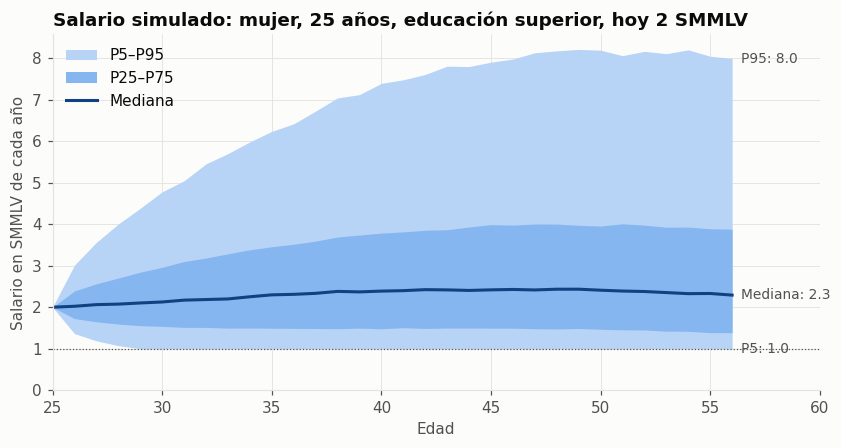

In [8]:
n = 57 - 25
smmlv = W.smmlv_real(n)
w = np.maximum(m.simular(25, "Mujer", "Superior", n, 10_000, salario_actual=2 * SMMLV_2026,
                         smmlv_actual=SMMLV_2026, seed=7), smmlv) / smmlv
edades = 25 + np.arange(n)
q = np.percentile(w, [5, 25, 50, 75, 95], axis=0)
fig, ax = plt.subplots()
ax.fill_between(edades, q[0], q[4], color=AZUL["150"], lw=0, label="P5–P95")
ax.fill_between(edades, q[1], q[3], color=AZUL["250"], lw=0, label="P25–P75")
ax.plot(edades, q[2], color=AZUL["650"], label="Mediana")
for i, lab in [(0, "P5"), (2, "Mediana"), (4, "P95")]:
    ax.annotate(f"{lab}: {q[i, -1]:.1f}", (edades[-1], q[i, -1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
ax.axhline(1, color=INK2, lw=0.8, ls=":")
ax.set_xlim(25, 60)
ax.set_ylim(0)
ax.set_xlabel("Edad")
ax.set_ylabel("Salario en SMMLV de cada año")
ax.set_title("Salario simulado: mujer, 25 años, educación superior, hoy 2 SMMLV")
ax.legend(loc="upper left")
plt.show()

### 4.2 Reversión a la media: dos hombres de 30 años con educación media

Uno gana 1,5 SMMLV y otro 3 SMMLV. Como casi toda la dispersión de este grupo es permanente o muy persistente, la diferencia entre ambos casi no se cierra con el tiempo.

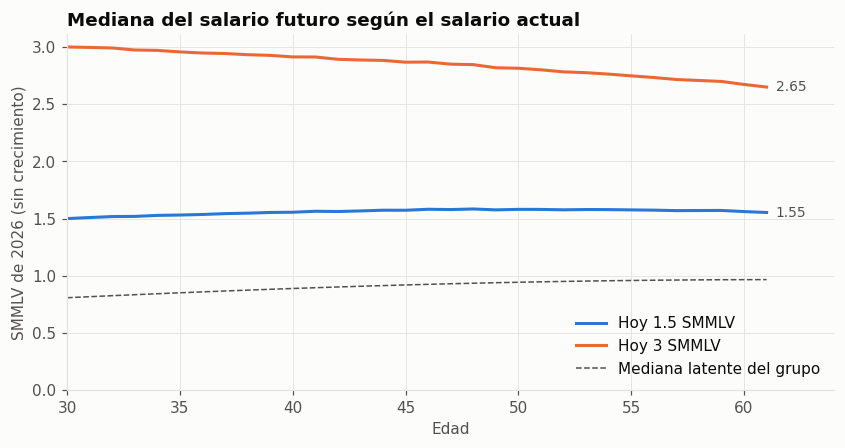

In [9]:
fig, ax = plt.subplots()
edades = 30 + np.arange(32)
for i, x in enumerate([1.5, 3.0]):
    w = m.simular(30, "Hombre", "Media", 32, 10_000, salario_actual=x * SMMLV_2026, smmlv_actual=SMMLV_2026,
                  crecimiento=0.0, seed=8)
    med = np.median(w, axis=0) / SMMLV_2026
    ax.plot(edades, med, color=SERIES[i], label=f"Hoy {x:g} SMMLV")
    ax.annotate(f"{med[-1]:.2f}", (edades[-1], med[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
med_tipo = np.exp(m.log_media(edades, "Hombre", "Media")) / SMMLV_2026
ax.plot(edades, med_tipo, color=INK2, lw=1, ls="--", label="Mediana latente del grupo")
ax.set_xlim(30, 64)
ax.set_ylim(0)
ax.set_xlabel("Edad")
ax.set_ylabel("SMMLV de 2026 (sin crecimiento)")
ax.set_title("Mediana del salario futuro según el salario actual")
ax.legend(loc="lower right")
plt.show()

## Hallazgos

1. **El salario mínimo pesa mucho en la pensión:** 4 de cada 10 cotizantes ganan el mínimo (contando a quienes lo declaran con el auxilio de transporte), y en los grupos sin educación superior son entre el 58 % y el 80 %. Para ellos el IBC es el mínimo durante casi toda la vida, así que su pensión depende más de las **semanas cotizadas** y de la **garantía de pensión mínima** que de la rentabilidad del fondo.
2. **El aumento de 2026 cambia el punto de partida:** en pesos de 2026, la mediana latente de los grupos sin educación superior queda *por debajo* del nuevo mínimo (17 % de aumento real). En 2026 aún más cotizantes quedan en el piso.
3. **Los choques salariales son muy persistentes** (ρ ≈ 0,95–0,995). Una persona que hoy gana más que su grupo probablemente lo siga haciendo, así que condicionar en el salario actual cambia mucho la pensión proyectada.
4. **Educación superior: más alto, más empinado y más disperso.** La mediana pasa de ~1,2 SMMLV a los 25 años a ~2–2,5 SMMLV hacia los 50–55, con choques anuales 2 a 3 veces más grandes que en los otros grupos.
5. **El modelo reproduce la sección transversal de 2025:** error medio de 1,8 % en la mediana y de 6,6 % en el P90 por tipo y edad, y sobreestima en ~3 puntos la proporción en el mínimo.
6. **Tratar el auxilio de transporte importa:** sin él (umbral de 1,05 SMMLV) los errores eran casi el doble (3,4 % en la mediana, 9,3 % en el P90, 5 puntos en el mínimo), porque el amontonamiento en 1,12–1,16 SMMLV se trataba como salario "libre".

**Limitaciones:** el perfil es de corte transversal (2022–2025), así que mezcla efectos de edad y de cohorte. Se asume que el error de medición del ingreso declarado es parte del componente permanente, y solo se observa a quienes cotizan (no se corrige la selección).